<a href="https://colab.research.google.com/github/Armaan245/BioGuardian/blob/main/BioGuardian_CV_Bubble_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q ultralytics opencv-python matplotlib pillow numpy

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 23.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 88.7/88.7 kB 4.2 MB/s eta 0:00:00


In [2]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

os.makedirs("synthetic_chip_dataset/images", exist_ok=True)

# Pixel Scale: 1 px = 2 micrometers (um)
MICRONS_PER_PIXEL = 2.0

def generate_bioguardian_chip_frame(image_id):
    # Base 512x512 microfluidic view
    img = np.ones((512, 512, 3), dtype=np.uint8) * 20

    # 1. Main Fluidic Channel (500 um width = 250 px wide)
    cv2.rectangle(img, (131, 20), (381, 180), (80, 50, 15), -1)
    cv2.rectangle(img, (131, 20), (381, 180), (180, 180, 180), 2)
    cv2.putText(img, "Main Channel (500um)", (140, 40), cv2.FONT_HERSHEY_SIMPLEX, 0.4, (200, 200, 200), 1)

    # 2. Bubble Trap Expansion Chamber (1500 um width = 450 px wide zone)
    cv2.rectangle(img, (31, 220), (481, 490), (100, 60, 20), -1)
    cv2.rectangle(img, (31, 220), (481, 490), (220, 220, 220), 2)
    cv2.putText(img, "Bubble Trap Chamber (1500um)", (40, 240), cv2.FONT_HERSHEY_SIMPLEX, 0.4, (220, 220, 220), 1)

    # 3. Simulate Biological Cell Layer on membrane
    for _ in range(400):
        cx, cy = np.random.randint(45, 467, 2)
        if cy > 250:
            cv2.circle(img, (cx, cy), np.random.randint(3, 7), (30, 160, 40), -1)

    # 4. Trapped Microbubbles (20 um to 100 um diameter -> 5 px to 25 px radius)
    num_bubbles = np.random.randint(2, 6)
    for _ in range(num_bubbles):
        bx = np.random.randint(60, 450)
        by = np.random.randint(260, 470)
        radius_px = np.random.randint(5, 25) # 20 um to 100 um

        cv2.circle(img, (bx, by), radius_px, (240, 240, 240), 2)
        cv2.circle(img, (bx - 2, by - 2), int(radius_px * 0.35), (255, 255, 255), -1)

    filename = f"synthetic_chip_dataset/images/frame_{image_id:03d}.jpg"
    cv2.imwrite(filename, img)
    return filename

# Generate 5 test frames
for i in range(5):
    generate_bioguardian_chip_frame(i)

print("Generated BioGuardian chip simulation frames successfully!")

Generated BioGuardian chip simulation frames successfully!


=== BIOGUARDIAN VISION TELEMETRY METRICS ===
Detected Microbubbles: 1
Chamber Occlusion: 0.04% Area Blocked
Flow Disruption Status: NORMAL


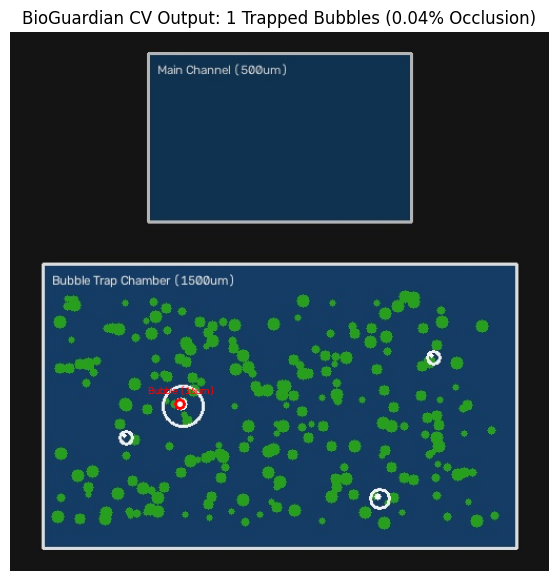

In [3]:
def analyze_bioguardian_frame(image_path):
    img = cv2.imread(image_path)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # 1. Isolate bright bubble artifacts using adaptive thresholding
    blurred = cv2.GaussianBlur(gray, (7, 7), 2)
    _, thresh = cv2.threshold(blurred, 210, 255, cv2.THRESH_BINARY)

    # 2. Extract contours representing microbubbles
    contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    bubble_count = 0
    total_bubble_area_px = 0
    annotated_img = img.copy()

    for cnt in contours:
        area = cv2.contourArea(cnt)
        # Filter noise based on realistic pixel size range (20um - 100um bubble area)
        if 15 < area < 2000:
            (x, y), radius = cv2.minEnclosingCircle(cnt)
            center = (int(x), int(y))
            radius = int(radius)

            # Draw red detection ring around trapped bubble
            cv2.circle(annotated_img, center, radius, (0, 0, 255), 2)
            cv2.putText(annotated_img, f"Bubble ({int(radius * 2 * MICRONS_PER_PIXEL)}um)",
                        (int(x) - 30, int(y) - radius - 5),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.35, (0, 0, 255), 1)

            bubble_count += 1
            total_bubble_area_px += area

    # 3. Calculate occlusion percentage inside the 1500 um Trap Chamber Area
    trap_chamber_area_px = (481 - 31) * (490 - 220) # 450px * 270px
    blocked_pct = round((total_bubble_area_px / trap_chamber_area_px) * 100, 2)

    return annotated_img, bubble_count, blocked_pct

# Run analysis on frame_000
annotated_frame, count, blocked_area = analyze_bioguardian_frame("synthetic_chip_dataset/images/frame_000.jpg")

print(f"=== BIOGUARDIAN VISION TELEMETRY METRICS ===")
print(f"Detected Microbubbles: {count}")
print(f"Chamber Occlusion: {blocked_area}% Area Blocked")
print(f"Flow Disruption Status: {'CRITICAL' if blocked_area > 5 else 'NORMAL'}")

# Display annotated frame
plt.figure(figsize=(7, 7))
plt.imshow(cv2.cvtColor(annotated_frame, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title(f"BioGuardian CV Output: {count} Trapped Bubbles ({blocked_area}% Occlusion)")
plt.show()

In [4]:
import json

# Package CV metrics into Digital Twin Telemetry Payload
cv_telemetry_payload = {
    "chip_id": "BioGuardian_PrepChip_01",
    "frame_id": "frame_000.jpg",
    "detected_bubbles": count,
    "chamber_occlusion_pct": blocked_area,
    "flow_status": 'CRITICAL' if blocked_area > 5.0 else 'NORMAL',
    "microns_per_pixel": MICRONS_PER_PIXEL
}

# Print JSON stream for backend consumption
print("=== TELEMETRY PAYLOAD FOR DIGITAL TWIN BACKEND ===")
print(json.dumps(cv_telemetry_payload, indent=4))

=== TELEMETRY PAYLOAD FOR DIGITAL TWIN BACKEND ===
{
    "chip_id": "BioGuardian_PrepChip_01",
    "frame_id": "frame_000.jpg",
    "detected_bubbles": 1,
    "chamber_occlusion_pct": 0.04,
    "flow_status": "NORMAL",
    "microns_per_pixel": 2.0
}
